# ENDICEX — Distribución territorial de los conglomerados K1–K5

Este cuaderno reproduce el **mapa geoespacial de las 111 entidades de ENDICEX** a partir de los resultados estadísticos definitivos del archivo **`ENDICEX_Resultados_PCA_Kmeans_K5.xlsx`**, hoja **`Base_111`** (encabezados en la cuarta fila).

Se distinguen las **101 entidades clasificadas en K1–K5** y las **10 sin cuentas rendidas de 2024** (cuatro que rindieron 2023 y seis sin rendición en ninguno de los dos ejercicios). El gráfico mantiene la paleta cromática definitiva, incorpora un recuadro de Canarias y sitúa expresamente Ceuta y Melilla.

**Fuentes:** resultados de ENDICEX y recintos administrativos oficiales del **IGN/CNIG**. Para disponer de los polígonos y límites territoriales, se utiliza además el archivo original **`lineas_limite.zip`** del IGN/CNIG. El notebook solicita ambos ficheros en Google Colab cuando no los encuentra en la carpeta de trabajo. **No se recalculan PCA ni K-means ni se construyen índices de prioridad.**

Los datos están **seudonimizados, no anonimizados**: el código INE y la posición geográfica permiten identificar las entidades. El mapa es descriptivo, de carácter exploratorio, y no constituye un hallazgo de fiscalización.


In [1]:
### 1. Configuración de fuentes, paleta y salidas
# El Excel ENDICEX aporta los resultados; el ZIP IGN, las geometrías.
# No se repite el muestreo inicial ni se recalculan los modelos.

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import shutil
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

EXCEL = 'ENDICEX_Resultados_PCA_Kmeans_K5.xlsx'
ZIP_IGN = 'lineas_limite.zip'
HOJA = 'Base_111'
CARPETA_SALIDA = Path('ENDICEX_Mapa_Resultados')
CARPETA_SALIDA.mkdir(exist_ok=True)

COLORES_K = {
    'K1': '#007CB9', 'K2': '#65AC34', 'K3': '#EDC446',
    'K4': '#FF8A16', 'K5': '#F93F45',
}
TAMANOS_K = {'K1': 13, 'K2': 48, 'K3': 32, 'K4': 4, 'K5': 4}
ORDEN_K = tuple(COLORES_K)
COLOR_SOLO_2023 = '#B76446'
COLOR_NINGUNA = '#A72C55'
NOMBRE_FIGURA = 'ENDICEX_Mapa_Geoespacial_K1_K5'


def localizar_archivo(nombre):
    """Busca primero el nombre exacto y solicita una carga si no está."""
    ruta = Path(nombre)
    if ruta.is_file():
        return ruta
    ruta_content = Path('/content') / ruta.name
    if ruta_content.is_file():
        return ruta_content
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            f'Falta {nombre}. Ponlo en la carpeta de ejecución.'
        ) from exc
    print(f'Sube ahora el archivo: {nombre}')
    subidos = files.upload()
    if len(subidos) != 1:
        raise ValueError('Sube un único archivo cada vez.')
    archivo = Path(next(iter(subidos)))
    if archivo.suffix.lower() != ruta.suffix.lower():
        raise ValueError(f'Se esperaba un archivo {ruta.suffix}.')
    return archivo

print('Salida de figuras:', CARPETA_SALIDA.resolve())

Salida de figuras: /content/ENDICEX_Mapa_Resultados


In [2]:
### 2. Lectura del Excel definitivo y controles de integridad
# Se verifican los 111 códigos INE, los 101 perfiles definitivos y las
# 10 entidades sin rendición 2024. Ceuta y Melilla permanecen en K-means.

ruta_excel = localizar_archivo(EXCEL)
base = pd.read_excel(
    ruta_excel, sheet_name=HOJA, header=3,
    dtype={'codigo_ine': 'string'}
)
obligatorias = ['codigo_ine', 'id_aleatorio', 'provincia',
                'Cluster K-means K5', 'cuentas 24', 'Cuentas 23']
faltan = sorted(set(obligatorias) - set(base.columns))
if faltan:
    raise ValueError('Faltan columnas en Base_111: ' + ', '.join(faltan))

base['codigo_ine'] = base['codigo_ine'].str.strip().str.zfill(5)
for campo in ('cuentas 24', 'Cuentas 23'):
    base[campo] = pd.to_numeric(base[campo], errors='coerce')

if len(base) != 111 or base['codigo_ine'].isna().any():
    raise ValueError('Base_111 debe contener 111 registros con código INE.')
if base['codigo_ine'].nunique() != 111:
    raise ValueError('Hay códigos INE duplicados en Base_111.')
if not base['codigo_ine'].str.fullmatch(r'\d{5}').all():
    raise ValueError('Existen códigos INE con formato incorrecto.')

clasificados = base['Cluster K-means K5'].isin(ORDEN_K)
no_rindieron = base['cuentas 24'].eq(0) & base['Cluster K-means K5'].isna()
solo_2023 = no_rindieron & base['Cuentas 23'].eq(1)
sin_ambas = no_rindieron & base['Cuentas 23'].eq(0)
if (int(clasificados.sum()), int(no_rindieron.sum()),
        int(solo_2023.sum()), int(sin_ambas.sum())) != (101, 10, 4, 6):
    raise ValueError('Recuento incompatible con ENDICEX: 101 + 4 + 6.')
if base.loc[clasificados, 'Cluster K-means K5'].value_counts().to_dict() != TAMANOS_K:
    raise ValueError('La distribución de K1–K5 no coincide con la solución auditada.')
if not base.loc[clasificados, 'cuentas 24'].eq(1).all():
    raise ValueError('Hay entidades clasificadas sin cuentas 2024.')
if not {'51001', '52001'}.issubset(
    set(base.loc[clasificados, 'codigo_ine'])
):
    raise ValueError('Ceuta y Melilla deben figurar entre las 101 clasificadas.')

base['categoria_mapa'] = np.select(
    [clasificados, solo_2023, sin_ambas],
    [base['Cluster K-means K5'].fillna(''), 'Solo 2023', 'Sin 2023 ni 2024'],
    default='ERROR'
)
if base['categoria_mapa'].eq('ERROR').any():
    raise ValueError('Existen entidades sin categoría cartográfica válida.')

print('Excel validado:', ruta_excel.name)
print('111 entidades = 101 K1–K5 + 4 solo 2023 + 6 sin 2023 ni 2024')
print('Perfiles:', base.loc[clasificados, 'Cluster K-means K5'].value_counts().sort_index().to_dict())

Sube ahora el archivo: ENDICEX_Resultados_PCA_Kmeans_K5.xlsx


Saving ENDICEX_Resultados_PCA_Kmeans_K5.xlsx to ENDICEX_Resultados_PCA_Kmeans_K5.xlsx
Excel validado: ENDICEX_Resultados_PCA_Kmeans_K5.xlsx
111 entidades = 101 K1–K5 + 4 solo 2023 + 6 sin 2023 ni 2024
Perfiles: {'K1': 13, 'K2': 48, 'K3': 32, 'K4': 4, 'K5': 4}


In [6]:

### 3. Cartografía oficial IGN/CNIG y correspondencia por código INE
# Fuente: Instituto Geográfico Nacional (IGN) / Centro Nacional de
# Información Geográfica (CNIG).
# Producto: Límites municipales, provinciales y autonómicos.
# Archivo: LINEAS_LIMITE.ZIP (formato Shapefile).
# Edición de referencia: 28/07/2026.
#
# Descarga oficial:
# https://centrodedescargas.cnig.es/CentroDescargas/detalleArchivo?sec=9000029
#
# Instrucciones:
# 1. Acceder al enlace oficial y descargar LINEAS_LIMITE.ZIP.
# 2. Mantener el archivo comprimido, sin extraer su contenido.
# 3. Subirlo a Google Colab cuando el notebook lo solicite.
#
# Se extraen cuatro capas de recintos municipales y provinciales,
# correspondientes a la Península/Baleares y Canarias.
# Las geometrías se transforman a EPSG:4326 y se cruzan con las
# 111 entidades de ENDICEX mediante sus códigos INE.
# Se comprueba la integridad de las correspondencias y se obtienen
# puntos interiores para representar las entidades en el mapa.
#
# Fuente cartográfica: Obra derivada de BDLJE CC-BY 4.0 ign.es.

URL_IGN = (
    "https://centrodedescargas.cnig.es/"
    "CentroDescargas/detalleArchivo?sec=9000029"
)

print("Cartografía oficial IGN/CNIG:")
print("Archivo requerido:", ZIP_IGN)
print("Descarga:", URL_IGN)

ruta_zip = localizar_archivo(ZIP_IGN)

CAPAS = {
    'municipios_pen': 'recintos_municipales_inspire_peninbal_etrs89',
    'municipios_can': 'recintos_municipales_inspire_canarias_wgs84',
    'provincias_pen': 'recintos_provinciales_inspire_peninbal_etrs89',
    'provincias_can': 'recintos_provinciales_inspire_canarias_wgs84',
}
CARPETA_IGN = Path('ENDICEX_Cartografia_IGN')
CARPETA_IGN.mkdir(exist_ok=True)


def extraer_shapefile(z, nombre_capa, destino):
    """Extrae componentes requeridos de una capa, sin depender del árbol ZIP."""
    extensiones = {'.shp', '.shx', '.dbf', '.prj', '.cpg'}
    candidatos = [m for m in z.namelist()
                  if Path(m).stem.casefold() == nombre_capa.casefold()
                  and Path(m).suffix.lower() in extensiones]
    mapa = {}
    for m in candidatos:
        ext = Path(m).suffix.lower()
        if ext in mapa:
            raise ValueError(f'Hay varios archivos {ext} para {nombre_capa}.')
        mapa[ext] = m
    faltan = {'.shp', '.shx', '.dbf', '.prj'} - set(mapa)
    if faltan:
        raise FileNotFoundError(
            f'El ZIP IGN carece de {nombre_capa} ({sorted(faltan)}). '
            'Comprueba que contiene los recintos municipales y provinciales.'
        )
    carpeta = destino / nombre_capa
    carpeta.mkdir(parents=True, exist_ok=True)
    for ext, miembro in mapa.items():
        destino_fichero = carpeta / f'{nombre_capa}{ext}'
        with z.open(miembro) as origen, destino_fichero.open('wb') as salida:
            shutil.copyfileobj(origen, salida)
    return carpeta / f'{nombre_capa}.shp'


with ZipFile(ruta_zip) as z:
    rutas_ign = {k: extraer_shapefile(z, v, CARPETA_IGN)
                 for k, v in CAPAS.items()}

municipios_partes = []
for nombre in ('municipios_pen', 'municipios_can'):
    parte = gpd.read_file(rutas_ign[nombre])
    if parte.crs is None or 'NATCODE' not in parte:
        raise ValueError(f'Capa IGN sin CRS o NATCODE: {nombre}')
    parte['codigo_ine'] = parte['NATCODE'].astype('string').str[-5:].str.zfill(5)
    municipios_partes.append(parte[['codigo_ine', 'geometry']].to_crs('EPSG:4326'))

municipios = gpd.GeoDataFrame(
    pd.concat(municipios_partes, ignore_index=True),
    geometry='geometry', crs='EPSG:4326'
)
# Solo interesa la muestra; así se diagnostican duplicidades pertinentes.
municipios = municipios.loc[municipios.codigo_ine.isin(base.codigo_ine)].copy()
if municipios.codigo_ine.duplicated().any():
    duplicados = municipios.loc[municipios.codigo_ine.duplicated(), 'codigo_ine'].tolist()
    raise ValueError(f'Códigos INE duplicados en la cartografía: {duplicados}')

seleccion = municipios.merge(base, on='codigo_ine', how='inner', validate='one_to_one')
seleccion = gpd.GeoDataFrame(seleccion, geometry='geometry', crs='EPSG:4326')
faltantes_ign = sorted(set(base.codigo_ine) - set(seleccion.codigo_ine))
if len(seleccion) != 111 or faltantes_ign:
    raise ValueError(
        f'IGN: {len(seleccion)}/111 geometrías disponibles. '
        f'Códigos no encontrados: {faltantes_ign}. '
        'Revisa la edición del ZIP de límites administrativos.'
    )

# representative_point() ofrece un punto interior, a diferencia del centroide.
proyectados = seleccion.to_crs('EPSG:3035')
puntos = proyectados.set_geometry(
    proyectados.geometry.representative_point()
).to_crs('EPSG:4326')
for codigo, punto in zip(puntos.codigo_ine, puntos.geometry):
    recinto = seleccion.loc[seleccion.codigo_ine.eq(codigo), 'geometry'].iloc[0]
    if not recinto.covers(punto):
        raise ValueError(f'El punto {codigo} queda fuera de su recinto IGN.')

prov_principal = gpd.read_file(rutas_ign['provincias_pen']).to_crs('EPSG:4326')
prov_can = gpd.read_file(rutas_ign['provincias_can']).to_crs('EPSG:4326')
if 'NATCODE' not in prov_principal:
    raise ValueError('Falta NATCODE en las provincias del IGN.')
prov_principal['codprov'] = prov_principal['NATCODE'].astype('string').str[-7:-5]
prov_principal = prov_principal.loc[
    ~prov_principal['codprov'].isin(['51', '52', '54'])
].copy()

puntos['codprov'] = puntos.codigo_ine.str[:2]
pen = puntos.loc[~puntos.codprov.isin(['35', '38'])].copy()
can = puntos.loc[puntos.codprov.isin(['35', '38'])].copy()

print('Geometrías municipales validadas:', len(puntos))
print('Canarias:', len(can), '· Mapa principal:', len(pen))
print('Ciudades autónomas:', sorted(set(puntos.codigo_ine) & {'51001', '52001'}))

Cartografía oficial IGN/CNIG:
Archivo requerido: lineas_limite.zip
Descarga: https://centrodedescargas.cnig.es/CentroDescargas/detalleArchivo?sec=9000029
Geometrías municipales validadas: 111
Canarias: 4 · Mapa principal: 107
Ciudades autónomas: ['51001', '52001']


Basemap no instalado: cartografía de fondo limitada a IGN/CNIG.


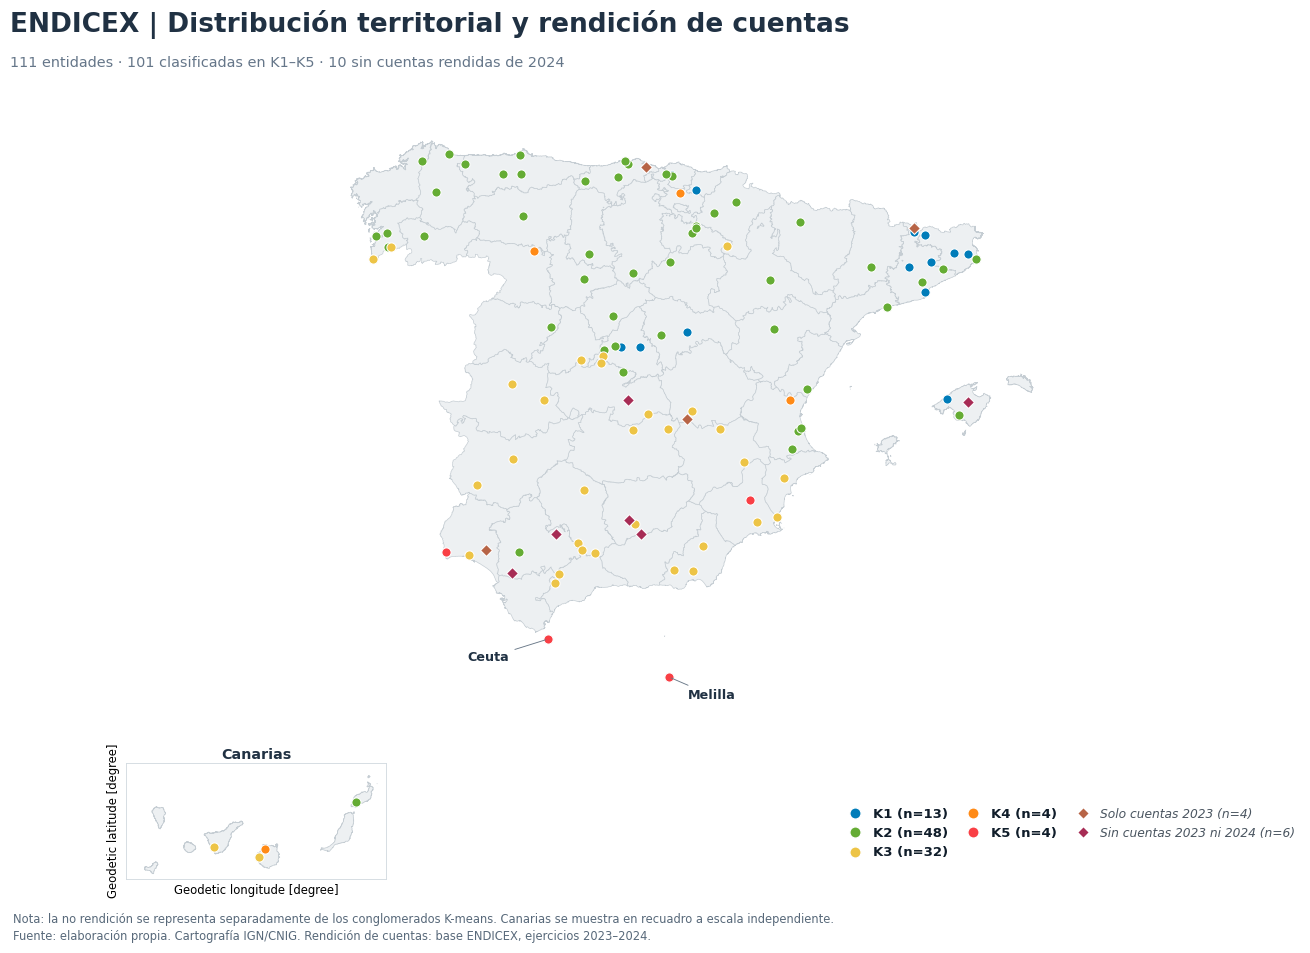

Mapa generado: 111 entidades, 7 categorías de representación.


In [4]:
### 4. Representación geoespacial y situación de rendición
# Se utilizan los colores K1–K5 definitivos; rombos marrón y granate para
# las 10 entidades sin rendición 2024, como en el panel C de ENDICEX.
# Canarias se sitúa en un recuadro; Ceuta y Melilla se identifican en el mapa.

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'svg.fonttype': 'none',
    'savefig.facecolor': 'white',
})

FONDO = '#EDF0F2'
BORDES = '#C5CDD3'
TEXTO = '#203143'

fig_mapa = plt.figure(figsize=(14.6, 9.7), facecolor='white')
fig_mapa.text(
    0.062, 0.963, 'ENDICEX | Distribución territorial y rendición de cuentas',
    fontsize=19, weight='bold', color=TEXTO, ha='left'
)
fig_mapa.text(
    0.062, 0.927,
    '111 entidades · 101 clasificadas en K1–K5 · 10 sin cuentas rendidas de 2024',
    fontsize=10.4, color='#657689', ha='left'
)

ax = fig_mapa.add_axes([0.085, 0.23, 0.86, 0.67])
ax.set_facecolor('white')

# Si Basemap está disponible, se conserva la costa GSHHG/NOAA original.
# En caso contrario el mapa sigue siendo válido con límites IGN/CNIG.
usa_costa_gshhg = False
try:
    from mpl_toolkits.basemap import Basemap
    costa = Basemap(
        projection='cyl', llcrnrlon=-10.6, llcrnrlat=34.25,
        urcrnrlon=4.8, urcrnrlat=44.55, resolution='i', ax=ax
    )
    costa.fillcontinents(color='#F6F5F3', lake_color='white', zorder=0)
    costa.drawcoastlines(color=BORDES, linewidth=0.54, zorder=1)
    usa_costa_gshhg = True
except ImportError:
    print('Basemap no instalado: cartografía de fondo limitada a IGN/CNIG.')

prov_principal.plot(ax=ax, color=FONDO, edgecolor=BORDES, linewidth=0.48, zorder=2)
ciudades = seleccion.loc[seleccion.codigo_ine.isin(['51001', '52001'])]
ciudades.plot(ax=ax, facecolor=FONDO, edgecolor='#96A2AD', linewidth=0.65, zorder=3)


def pintar_entidades(eje, datos, tamano=44):
    for k, col in COLORES_K.items():
        grupo = datos.loc[datos.categoria_mapa.eq(k)]
        if not grupo.empty:
            eje.scatter(grupo.geometry.x, grupo.geometry.y,
                        marker='o', s=tamano, color=col,
                        edgecolors='white', linewidths=0.75, zorder=6)
    # Los dos grupos de no rendición utilizan rombos, nunca círculos K-means.
    for etiqueta, color in [('Solo 2023', COLOR_SOLO_2023),
                           ('Sin 2023 ni 2024', COLOR_NINGUNA)]:
        grupo = datos.loc[datos.categoria_mapa.eq(etiqueta)]
        if not grupo.empty:
            eje.scatter(grupo.geometry.x, grupo.geometry.y,
                        marker='D', s=tamano*0.83, color=color,
                        edgecolors='white', linewidths=0.75, zorder=7)


pintar_entidades(ax, pen)
for codigo, nombre, delta, ha in [
    ('51001', 'Ceuta', (-28, -16), 'right'),
    ('52001', 'Melilla', (14, -16), 'left')
]:
    p = puntos.loc[puntos.codigo_ine.eq(codigo), 'geometry'].iloc[0]
    ax.annotate(nombre, (p.x, p.y), xytext=delta,
                textcoords='offset points', fontsize=9.2, color=TEXTO,
                weight='bold', ha=ha,
                arrowprops={'arrowstyle': '-', 'color': '#697888', 'lw': 0.65},
                zorder=10)

ax.set_xlim(-10.6, 4.8)
ax.set_ylim(34.25, 44.55)
ax.set_aspect(1.26, adjustable='box')
ax.axis('off')

# Recuadro de Canarias con límites propios (no es la misma escala del mapa principal).
ax_can = fig_mapa.add_axes([0.098, 0.090, 0.265, 0.119])
prov_can.plot(ax=ax_can, color=FONDO, edgecolor=BORDES, linewidth=0.53, zorder=1)
pintar_entidades(ax_can, can)
ax_can.set_xlim(-18.55, -13.15)
ax_can.set_ylim(27.55, 29.65)
ax_can.set_aspect(1.14, adjustable='box')
ax_can.set_title('Canarias', fontsize=10.3, color=TEXTO, weight='bold', pad=3)
ax_can.set_xticks([])
ax_can.set_yticks([])
for spine in ax_can.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor('#D3DBE1')
    spine.set_linewidth(0.65)

leyenda = [
    Line2D([], [], marker='o', linestyle='', markerfacecolor=col,
           markeredgecolor='white', markersize=8.1,
           label=f'{k} (n={TAMANOS_K[k]})')
    for k, col in COLORES_K.items()
]
leyenda += [
    Line2D([], [], marker='D', linestyle='', markerfacecolor=COLOR_SOLO_2023,
           markeredgecolor='white', markersize=6.5,
           label='Solo cuentas 2023 (n=4)'),
    Line2D([], [], marker='D', linestyle='', markerfacecolor=COLOR_NINGUNA,
           markeredgecolor='white', markersize=6.5,
           label='Sin cuentas 2023 ni 2024 (n=6)'),
]
leg = fig_mapa.legend(
    handles=leyenda, loc='lower right', bbox_to_anchor=(0.95, 0.099),
    ncol=3, frameon=False, fontsize=8.8,
    handletextpad=0.45, columnspacing=1.1
)
for t in leg.get_texts():
    if t.get_text().startswith(('K1', 'K2', 'K3', 'K4', 'K5')):
        t.set_weight('bold')
        t.set_fontsize(9.5)
        t.set_color('#101D2A')
    else:
        t.set_style('italic')
        t.set_color('#4A5560')

fuente_costa = '; costa GSHHG/NOAA' if usa_costa_gshhg else ''
fig_mapa.text(
    0.064, 0.039,
    'Nota: la no rendición se representa separadamente de los conglomerados K-means. '
    'Canarias se muestra en recuadro a escala independiente.\n'
    'Fuente: elaboración propia. Cartografía IGN/CNIG' + fuente_costa +
    '. Rendición de cuentas: base ENDICEX, ejercicios 2023–2024.',
    color='#58697A', fontsize=8.3, ha='left', va='center', linespacing=1.4
)

plt.show()
print('Mapa generado: 111 entidades, 7 categorías de representación.')

In [5]:
### 5. Exportación y descarga del mapa geoespacial
# Se guardan PNG (300 ppp), SVG vectorial y JPG, además de un ZIP conjunto.
# La descarga automática se realiza únicamente cuando se utiliza Google Colab.

if 'fig_mapa' not in globals():
    raise RuntimeError('Ejecuta primero el apartado 4 para generar el mapa.')

salidas = {
    'PNG': CARPETA_SALIDA / f'{NOMBRE_FIGURA}.png',
    'SVG': CARPETA_SALIDA / f'{NOMBRE_FIGURA}.svg',
    'JPG': CARPETA_SALIDA / f'{NOMBRE_FIGURA}.jpg',
}
for formato, ruta in salidas.items():
    argumentos = dict(bbox_inches='tight', facecolor='white', pad_inches=0.12)
    if formato != 'SVG':
        argumentos['dpi'] = 300
    fig_mapa.savefig(ruta, **argumentos)
    if not ruta.is_file():
        raise RuntimeError(f'No se ha creado {ruta}.')
    print(formato, 'generado:', ruta.resolve())

zip_salida = CARPETA_SALIDA / f'{NOMBRE_FIGURA}.zip'
with ZipFile(zip_salida, 'w', compression=ZIP_DEFLATED) as paquete:
    for ruta in salidas.values():
        paquete.write(ruta, arcname=ruta.name)
print('Paquete:', zip_salida.resolve())

try:
    from google.colab import files
except ImportError:
    print('Los archivos permanecen disponibles en la carpeta de salida.')
else:
    files.download(str(zip_salida))

PNG generado: /content/ENDICEX_Mapa_Resultados/ENDICEX_Mapa_Geoespacial_K1_K5.png
SVG generado: /content/ENDICEX_Mapa_Resultados/ENDICEX_Mapa_Geoespacial_K1_K5.svg
JPG generado: /content/ENDICEX_Mapa_Resultados/ENDICEX_Mapa_Geoespacial_K1_K5.jpg
Paquete: /content/ENDICEX_Mapa_Resultados/ENDICEX_Mapa_Geoespacial_K1_K5.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>